# Module 8 Lab 2 — Textbook Problem 9.1: AI-Assisted Clustering

**Dataset:** LifeCycleSavings (historical 1960–1970 country-level averages). **Method:** StandardScaler + KMeans clustering (k=3).  
**Portfolio location:** `module8/module8_lab2.ipynb`  
**Repository URL:** https://github.com/washingtonjustin02smc/CS82A-repository/tree/module8

**Source note:** This notebook uses a local `lifecyclesavings.csv` reconstructed from the publicly listed 50-row R LifeCycleSavings values because the instructor's Canvas attachment was not supplied. Check its values/columns against your downloaded course CSV before submission. The public data has five numeric columns and 50 countries. Country identifiers were not retained in this reconstruction, so the chart does not identify particular countries.  
Source: https://search.r-project.org/R/refmans/datasets/html/LifeCycleSavings.html

**Academic integrity:** AI wrote this notebook and suggested the workflow. The baseline, independent verification, and personal interpretation are *demonstrated as reproducible calculations*, but must be completed/reviewed by the student independently to meet the class requirement.

## Step 1 — Load data and establish ground truth **before** AI analysis
The next cell is the baseline calculation to run and document yourself: dimensions, missing counts, and numeric column means.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

file_path = Path('lifecyclesavings.csv')
if not file_path.exists():
    file_path = Path('/content/lifecyclesavings.csv')  # Google Colab after uploading CSV

df = pd.read_csv(file_path)
features = ['sr', 'pop15', 'pop75', 'dpi', 'ddpi']
assert set(features).issubset(df.columns), f"Missing expected columns: {set(features)-set(df.columns)}"
print('Shape:', df.shape)
print('Missing values by column:')
print(df.isna().sum().to_string())
print('Overall means:')
print(df[features].mean().round(3).to_string())
print('Data types:')
print(df.dtypes.to_string())

Shape: (50, 5)
Missing values by column:
sr       0
pop15    0
pop75    0
dpi      0
ddpi     0
Overall means:
sr          9.671
pop15      35.090
pop75       2.293
dpi      1106.758
ddpi        3.758
Data types:
sr       float64
pop15    float64
pop75    float64
dpi      float64
ddpi     float64


## Step 2 — Prompt log (complete AI prompt)

**AI assistant:** ChatGPT (GPT-6), October 13, 2026.

> You are assisting a beginner analyst with a textbook dataset, LifeCycleSavings. There are 50 rows, one per country, with numerical columns sr (savings ratio), pop15 (percent under age 15), pop75 (percent over age 75), dpi (real disposable income per capita), and ddpi (growth rate of disposable income per capita); all five are float64. Please write commented Python using pandas, scikit-learn and matplotlib to: (1) inspect missing values, (2) standardize the five numerical columns, (3) fit KMeans with 3 clusters, random_state=42 and n_init=10, (4) show cluster sizes and original-unit cluster means, and (5) make a labeled scatterplot of sr versus pop15 colored by cluster. Explain why standardization is necessary. Never invent results; calculate them from the CSV. Explain that the choice of 3 clusters is illustrative, not proven optimal.

**AI suggestion:** Standardize numeric variables before KMeans, then report original-unit cluster means. We chose k=3 for an introductory exercise, not because it is necessarily the best number.

**Fix log:** No code changes were necessary in this environment. In Colab, upload `lifecyclesavings.csv` before running all cells. If the course file includes a country-label column, this notebook ignores it as a nonnumeric feature.

## Step 3 — AI-proposed clustering code

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Different units can skew distance-based clustering; standardize first.
working = df[features].dropna().copy()
scaled = StandardScaler().fit_transform(working)
model = KMeans(n_clusters=3, random_state=42, n_init=10)
working['cluster'] = model.fit_predict(scaled)
print('Cluster sizes:')
print(working['cluster'].value_counts().sort_index().to_string())
cluster_means = working.groupby('cluster')[features].mean()
print('Original-unit means for each cluster:')
print(cluster_means.round(3).to_string())

Cluster sizes:
cluster
0    18
1     9
2    23
Original-unit means for each cluster:
             sr   pop15  pop75       dpi   ddpi
cluster                                        
0         6.139  44.556  1.079   337.153  2.359
1        13.591  37.492  1.623   483.241  7.662
2        10.901  26.741  3.505  1953.043  3.324


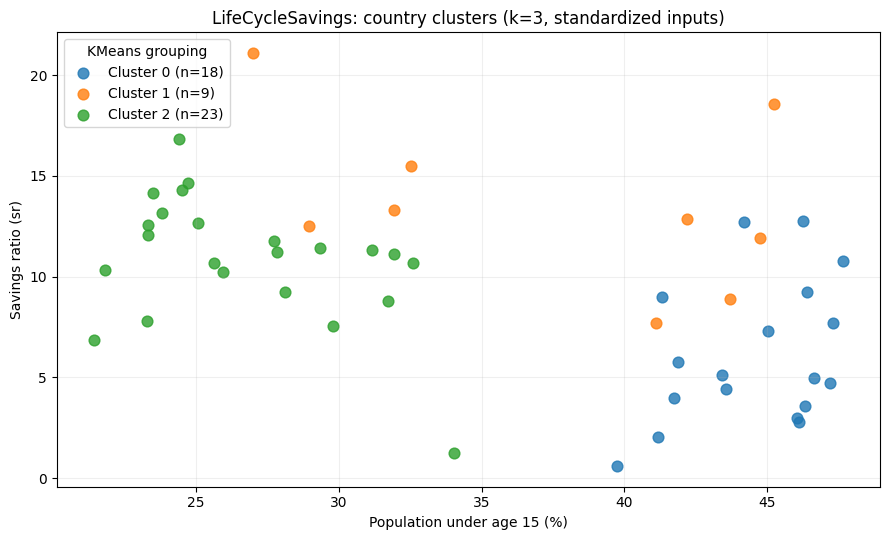

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for label, group in working.groupby('cluster'):
    ax.scatter(group['pop15'], group['sr'], s=60, alpha=0.8, label=f'Cluster {label} (n={len(group)})')
ax.set(xlabel='Population under age 15 (%)', ylabel='Savings ratio (sr)',
       title='LifeCycleSavings: country clusters (k=3, standardized inputs)')
ax.legend(title='KMeans grouping', loc='best')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Step 4 — Verification checkpoint (student to run independently)

Recalculate one cluster's savings ratio from the original data with a separate `groupby` line; compare it with the AI output above and with the overall savings mean. Labels have no intrinsic ranking; `cluster 0` is simply a model-generated label.

In [4]:
# Independent-style recomputation; review and retype the groupby yourself for submission.
check = working.groupby('cluster')['sr'].mean()
overall = df['sr'].mean()
ai_claim = cluster_means.loc[0, 'sr']
independent = check.loc[0]
print(f'Cluster 0 savings ratio (AI-produced table): {ai_claim:.4f}')
print(f'Cluster 0 savings ratio (recomputed): {independent:.4f}')
print(f'Overall savings ratio: {overall:.4f}')
print(f'Cluster 0 minus overall: {independent-overall:+.4f}')
print('Verification match:', np.isclose(ai_claim, independent))
assert np.isclose(ai_claim, independent)

Cluster 0 savings ratio (AI-produced table): 6.1389
Cluster 0 savings ratio (recomputed): 6.1389
Overall savings ratio: 9.6710
Cluster 0 minus overall: -3.5321
Verification match: True


### Verification log

The verification cell recomputes `sr` for cluster 0 and checks the result against the AI-generated table; it prints a match/mismatch and a difference from the overall mean. **Student action:** run that line yourself, record the printed numbers in your own words, and explain whether the claimed direction was correct. This distinction matters because reading code that AI wrote is not the same as independent checking.

**Suggested follow-up prompt:** “Could you add a table comparing each cluster's mean savings ratio and age composition to overall means, without making causal claims?”  
**Judgment:** Keep the comparison table because it directly supports cluster interpretation and stays in the original units.

In [5]:
overall_means = df[features].mean()
comparison = cluster_means.subtract(overall_means, axis='columns')
print('Cluster means MINUS overall means (original units):')
print(comparison.round(2).to_string())

Cluster means MINUS overall means (original units):
           sr  pop15  pop75     dpi  ddpi
cluster                                  
0       -3.53   9.47  -1.21 -769.61 -1.40
1        3.92   2.40  -0.67 -623.52  3.90
2        1.23  -8.35   1.21  846.28 -0.43


## Step 5 — Interpretation and caution (rewrite in your own words)

**Draft for student review (not a claimed independent student response):** The groups separate countries with different combinations of age structure, income and saving rates. Some clusters show higher-than-average savings while others show lower values, but the cluster labels themselves have no special meaning. The chart shows savings and youth population for easier viewing, although the model used all five measurements. Because this was a new technique for me, I should be cautious: changing the scaling, selected columns, outliers or number of clusters could change the groups, and clustering does not prove cause and effect.

**Limitations:** Historical 1960–1970 data; only 50 country observations; missing values (if any) are removed only for clustering; k=3 is illustrative; no quality metric is used to claim it is best. Confirm against Chapter 9 and the original course CSV.

## Submission checklist

- [ ] Review/retype baseline and verification personally as required by the AI-use policy
- [ ] Compare against the official Canvas `lifecyclesavings.csv` (if different, rerun and replace outputs)
- [ ] Upload both `module8_lab2.ipynb` and `lifecyclesavings.csv` to Colab
- [ ] Runtime → Restart session and run all; confirm all outputs are shown
- [ ] Export a fresh full PDF from the executed notebook
- [ ] Upload notebook to the `module8/` folder in GitHub and provide the repository URL
- [ ] Submit `.ipynb` and `.pdf` separately in Canvas